# CHP-2: weather-adjusted model

Idea: a model that only knows weather + calendar, trained on the coal years.
It tells how dirty a day "should" be with this weather if nothing changed.
After CHP-2 goes to gas, compare real PM2.5 with this.

Code is in `src/weather_model.py`, the weekly check is `src/chp2_tracker.py`.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import pandas as pd

from config import CHP2_SWITCH_DATE, FIGURES_DIR
from features import load_hourly
from weather_model import (coal_period, leave_one_winter_out, make_weather_table,
                           train_model, weather_columns)

plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
daily = make_weather_table(load_hourly())
print("switch date:", CHP2_SWITCH_DATE)
daily.shape

switch date: 2026-11-01


(2226, 26)

In [3]:
weather_columns()

['temp',
 'temp_min',
 'humidity',
 'wind',
 'pressure',
 'precipitation',
 'blh',
 'blh_min',
 'blh_night',
 'wind_night',
 'temp_yesterday',
 'blh_yesterday',
 'blh_night_yesterday',
 'wind_yesterday',
 'temp_3d',
 'dayofweek',
 'weekend',
 'holiday',
 'heating',
 'dayofyear']

## Can it guess a whole winter it has never seen?
For each winter: train on everything else, predict that winter.

In [4]:
past, preds = leave_one_winter_out(daily)
past

,winter,days,actual_mean,expected_mean,gap_percent
0,2020-21,116,67.1,49.6,35.4
1,2021-22,134,45.8,42.4,8.0
2,2022-23,121,53.2,47.5,11.9
3,2023-24,174,36.3,46.8,-22.5
4,2024-25,182,41.4,45.3,-8.6


In [5]:
# BLH is missing for Jan-Jun 2024, so try without it too
past_no_blh, _ = leave_one_winter_out(daily, use_blh=False)
past.merge(past_no_blh[["winter", "gap_percent"]], on="winter", suffixes=("", "_no_blh"))

,winter,days,actual_mean,expected_mean,gap_percent,gap_percent_no_blh
0,2020-21,116,67.1,49.6,35.4,41.6
1,2021-22,134,45.8,42.4,8.0,17.8
2,2022-23,121,53.2,47.5,11.9,23.1
3,2023-24,174,36.3,46.8,-22.5,-13.3
4,2024-25,182,41.4,45.3,-8.6,-13.1


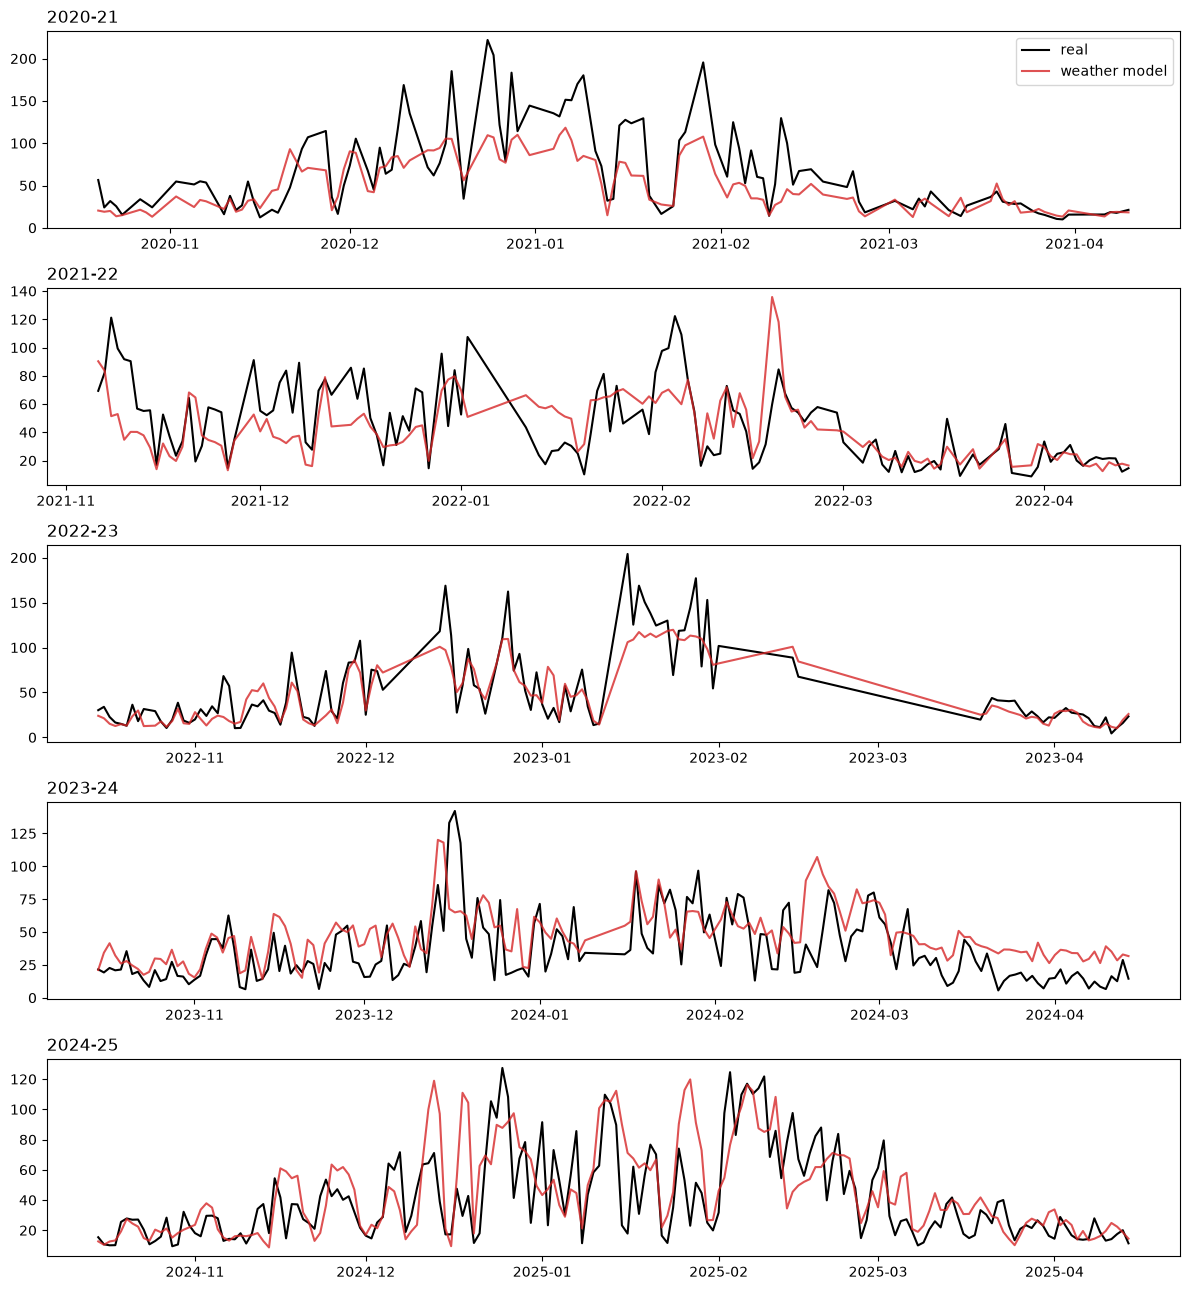

In [6]:
winters = preds.winter.unique()
fig, axes = plt.subplots(len(winters), 1, figsize=(12, 2.6 * len(winters)))
for ax, w in zip(axes, winters):
    part = preds[preds.winter == w]
    ax.plot(part.date, part.pm25, color="black", label="real")
    ax.plot(part.date, part.expected, color="tab:red", alpha=0.8, label="weather model")
    ax.set_title(w, loc="left")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "chp2_past_winters.png", dpi=120, bbox_inches="tight")

In [7]:
# day-level error. the whole-winter mean is what matters for CHP-2, but good to know
preds.assign(err=(preds.expected - preds.pm25).abs()).groupby("winter").err.mean().round(1)

winter
2020-21    24.9
2021-22    16.6
2022-23    14.6
2023-24    17.2
2024-25    15.5
Name: err, dtype: float64

## After the switch

In [8]:
after = daily[daily.date >= CHP2_SWITCH_DATE].dropna(subset=["pm25"])
print(len(after), "days after the switch")

if len(after):
    model = train_model(coal_period(daily))
    after = after.assign(expected=model.predict(after[weather_columns()]))
    print("real:", round(after.pm25.mean(), 1), "expected:", round(after.expected.mean(), 1))
    print("gap %:", round((after.pm25.mean() / after.expected.mean() - 1) * 100, 1))

0 days after the switch


## What is known so far

the switch hasn't happened yet, so nothing to compare. will update after it